In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

In [2]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    # dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [3]:
class Value:
    def __init__(self, data, label="", _children=(), _op=''):
        self.data = data
        self.label = label
        self.grad = 0
        self._prev = set(_children)
        self._op=_op
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op='+')

        def backward():
            self.grad += out.grad
            other.grad += out.grad
        
        out._backward = backward
        return out

    def __sub__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data - other.data, _children=(self, other), _op='-')

        def backward():
            self.grad += out.grad
            other.grad -= out.grad
        
        out._backward = backward
        return out

    def __radd__(self, other):
        return self + other

    def __rsub__(self, other):
        return self - other

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op='*')

        def backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data 
                
        out._backward = backward
        return out

    def __truediv__ (self, other):
        out = self * other**-1
        out._op = '/'
        return out

    def __pow__ (self, other):
        out = Value(self.data ** other, _children=(self, ), _op = '**')

        def backward():
            self.grad += other*self.data**(other-1) * out.grad
        out._backward = backward
        return out

    def tanh(self):
        n = self.data
        t = (math.exp(2*n)-1)/(math.exp(2*n)+1)
        out = Value(t, _children=(self, ), _op='tanh')

        def backward():
            self.grad += out.grad * (1-t**2)

        out._backward = backward
        
        return out

    def backward(self):
        self.grad = 1
        topo = []
        vis = set()
        def build_topo(node):
            if node in vis: return
            vis.add(node)
            for child in node._prev:
                build_topo(child)
            topo.append(node)

        build_topo(self)
        for idx in reversed(range(len(topo))):
            topo[idx]._backward()

In [4]:
class Neuron:
    def __init__(self, n_in):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w*x + b
        activation = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = activation.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]
    
class Layer:
    def __init__(self, n_in, n_out):
        self.neurons = [Neuron(n_in) for _ in range(n_out)]

    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out

    def parameters(self):
        params = []
        for neuron in self.neurons:
            params.extend(neuron.parameters())
        return params

class MLP:
    def __init__(self, n_in, n_outs):
        self.layers = [Layer(n_in, n_outs[0])]
        for i in range(1, len(n_outs)):
            self.layers.append(Layer(n_outs[i-1], n_outs[i]))

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        params = []
        for layer in self.layers:
            params.extend(layer.parameters())
        return params


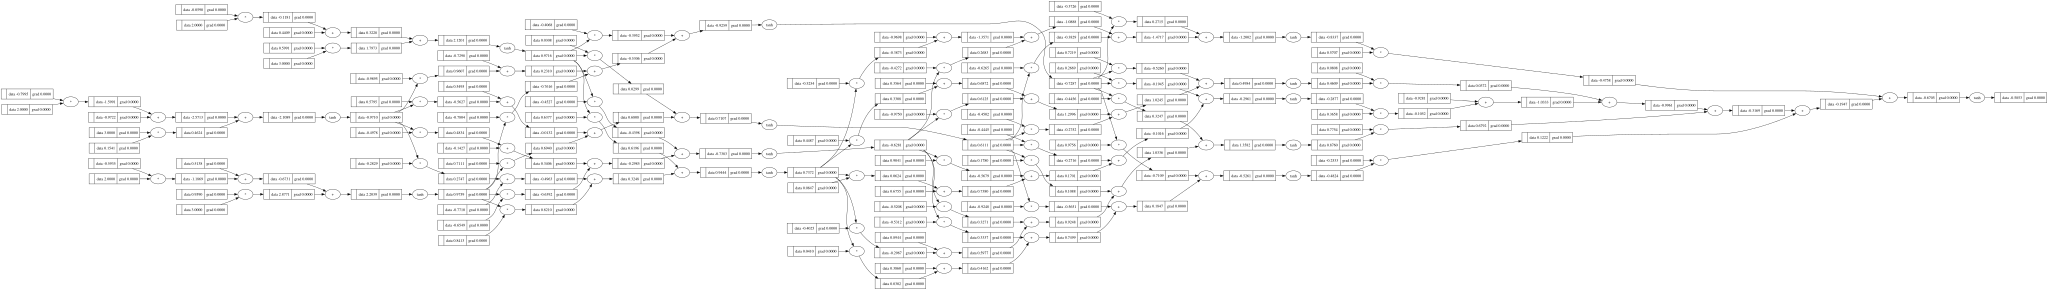

In [5]:
x = [2.0, 3.0]
m = MLP(2, [3,4,5,1])      
draw_dot(m(x)[0])

In [6]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
ypred = [m(x)[0] for x in xs]
ypred

[Value(data=-0.585280916663534),
 Value(data=-0.7126121664058176),
 Value(data=-0.5659193315052131),
 Value(data=-0.5591421922048864)]

In [7]:
def loss(targets, ypreds):
    return sum((y-t)**2 for t, y in zip(targets, ypreds))

In [ ]:
for i in range(100):
    ypred = [m(x)[0] for x in xs]
    diff = loss(ys, ypred)
    for param in m.parameters():
        param.grad = 0
    diff.backward()
    for param in m.parameters():
        param.data -= 0.01*param.grad
    print(diff)

(Value(data=2.7073972446592753),
 [Value(data=0.3428763272004006),
  Value(data=-0.8232440524154743),
  Value(data=0.33165835147638484),
  Value(data=0.3136844069654739)])